# Price tier prediction

A multiclass classification problem, aimed for predicting price tier of a work place with respect to its features set,
using simple ways to workwith complete end to end machine learning pipeline for making this sytem work. Dataset details,
walk through with complete roadmap with learning machine learning hands on.

**Real Life usecase**
Model is scoped stricly for academic purpose, But could be used in several ways
+ Working as ranking list engine for automated price prediction through scraped details about workspace
+ Listing strongness of work places with our own listing index
+ commercializing listing and improvement directions for workspace for our index range

Thus model could be integrated for a application for companies to manage there hybrid offices location.
rest core architechture and learning could be expanded for soo many problem scope.

In [2]:
# GLOBAL PARAMETERS

TRAIN_PATH = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/train.csv'
TEST_PATH = 'experiment/data/MLP-PROJECT-DATASET/test.csv'

# MODEL CONFIGS

## Exploratory data analysis

We would explore dataset with univariate approach with both categorical and numerical, 
implementing simple binning and aggregation perspective with dataset we would broadly follow simple rules

Simple univarite exploration
+ Plot univariate unit with single distribution
+ Plot the relation between target value with the feature of interest

In [3]:
# Basic data exploration
import pandas as pd 

df = pd.read_csv(TRAIN_PATH)

# Utility function for targeted relation plot

def relation_ploter(relation, size):
    ''' 
    Makes targeted distribution plot with alligned group df element
    relation_dataframe[grouping_element].groupby('price_tier')
    '''
    # Relation ploting tool
    fig, ax = plt.subplots(
        1, size, figsize=(15,2),
        layout='tight'
    )

    for i, (space_class, group_series) in enumerate(relation.groupby(level=0)):
        price_tier_counts = group_series.droplevel(0)
        price_tier_counts = price_tier_counts.sort_index()

        price_tier_counts.plot(
            kind='bar',
            ax=ax[i],
            color='darkblue',
            edgecolor='black'
        )
        ax[i].set_title(space_class)
        ax[i].set_xlabel("Target Class")
        ax[i].set_ylabel("Count")
        ax[i].tick_params(axis='x', rotation=0) # Keep x-labels upright


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  str    
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  str    
 7   operator_certified            279142 non-null  str    
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  str    
 10  operator_id_verified          279142 non-null  str    
 11  zone                          279746 non-null  str    
 12  borough                       65295 non-null   str    


Distribution of potential categorical | high cardinal feature


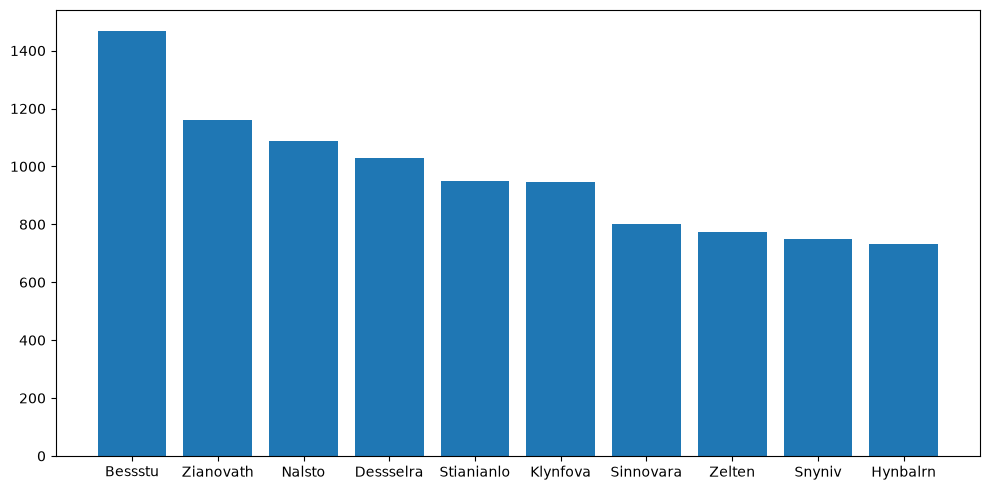

In [4]:
'''
Targeted variable for exploration
operator_ref, operator_class, space_class

Kernel Crash during plot
With 41 thousand reference unique,
we cant direct plot those numbers

Potential dropout with operator_ref
covering with 14 percent on total dataset size

Potential imputation with distribution of these refrences
with other based binning for rest of non-common elements
'''
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

ref_data = df.loc[:, 'operator_ref'].dropna()

# top 10 ranker of referals
rankers = ref_data.value_counts()[:10]
plt.figure(figsize=(10,5))
plt.bar(
    rankers.index, 
    rankers,
    width=0.8
)
plt.tight_layout()
print("Distribution of potential categorical | high cardinal feature")

feature scope : <StringArray>
['independent_operator', 'unverified_operator', 'managed_operator']
Length: 3, dtype: str


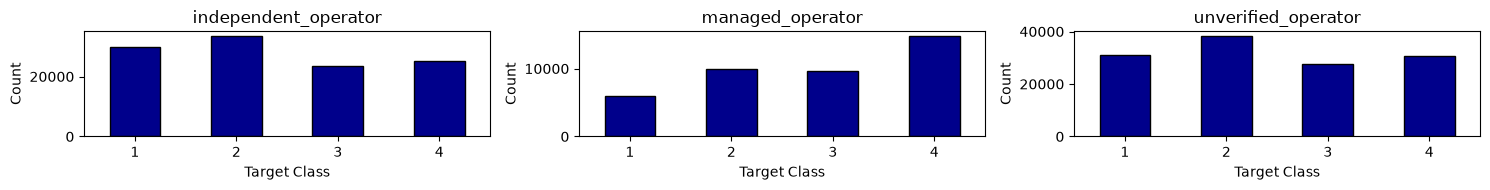

In [5]:
# Target : oprator_class

feature = df['operator_class'].dropna()
scope = feature.unique()
print(f"feature scope : {scope}")

# How is the all three classes are distributed ?
distribution = feature.value_counts()

# what is the relation of operator_class with target feature ?
relation = df.groupby('operator_class')['price_tier'].value_counts().sort_values()

relation_ploter(relation, size=3)

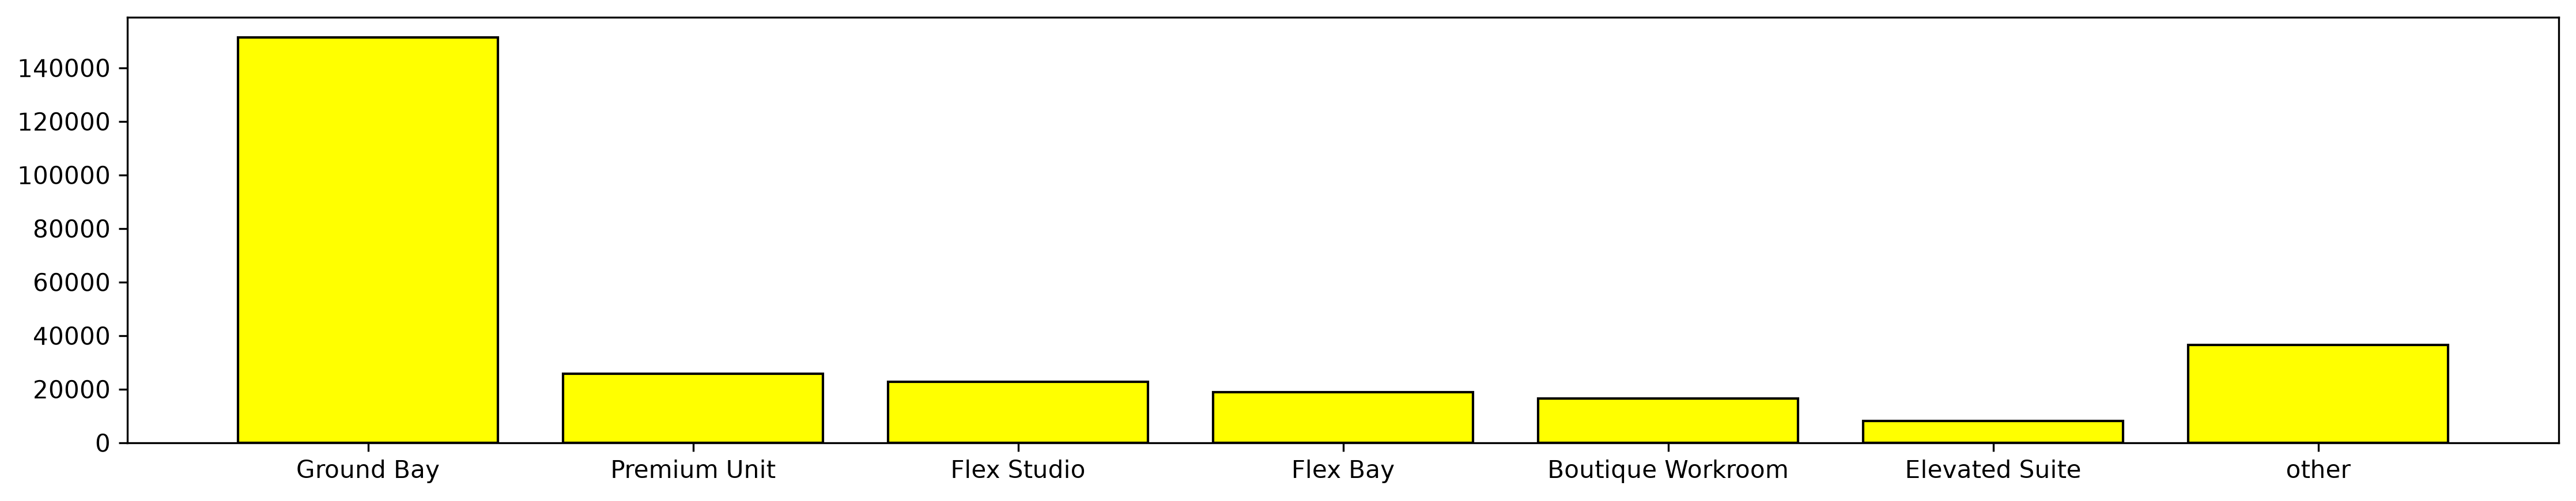

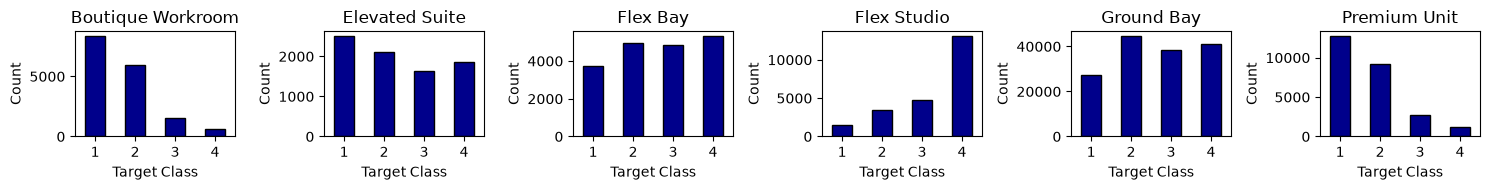

In [6]:
# Exploring space class distribution

feature = df['space_class'].dropna()
#print(f"Looking with distribution of the values with class : {feature.unique()}")

size = 6
# Grouping elements with value counting ranking
values = feature.value_counts(ascending=False)

# top ranker data
rankers = list(values.index[:size])
freq = list(values[:size])

# Leading other bin
other_sum = values[size:].sum()
rankers.append('other')

freq.append(other_sum)
plt.figure(figsize=(15,3), dpi=300)
plt.bar(
    x=rankers,
    height=freq,
    color='yellow',
    edgecolor='black'
)
plt.tight_layout()

# realtion of feature rankers with price tier
space_classing = df[
    df['space_class'].isin(rankers[:-1])
]

space_class_relation = space_classing.groupby(
    'space_class'
)['price_tier'].value_counts()

relation_ploter(space_class_relation, size=size)

In [7]:
# Facilities exploration is requried could be potential very strong feature

### Categorical EDA report 📑

With given set of features, we can see some really nice insights about picked features,
operator_ref contains really big number of elements which makes it non-ideal for seting up with one-hot encoding, dataset contains high variability, along with thousand of features, thus in first place it looked as promising feature to have but now its leaning towards droping

With `operator_class` we assumed to have good directive distribution with the target feature where it contains slight featuring with target features. we would approach for making its onehot encoding through which model might benifit with its certain neiche distribution pattern we see in plot

With space_class distribution plot we can see really strong pattern of followup, features are trending with one perticular class with perticular space class, which is really good for making them with targeted encoding for featuring them into the next plot with OneHot encoding set.

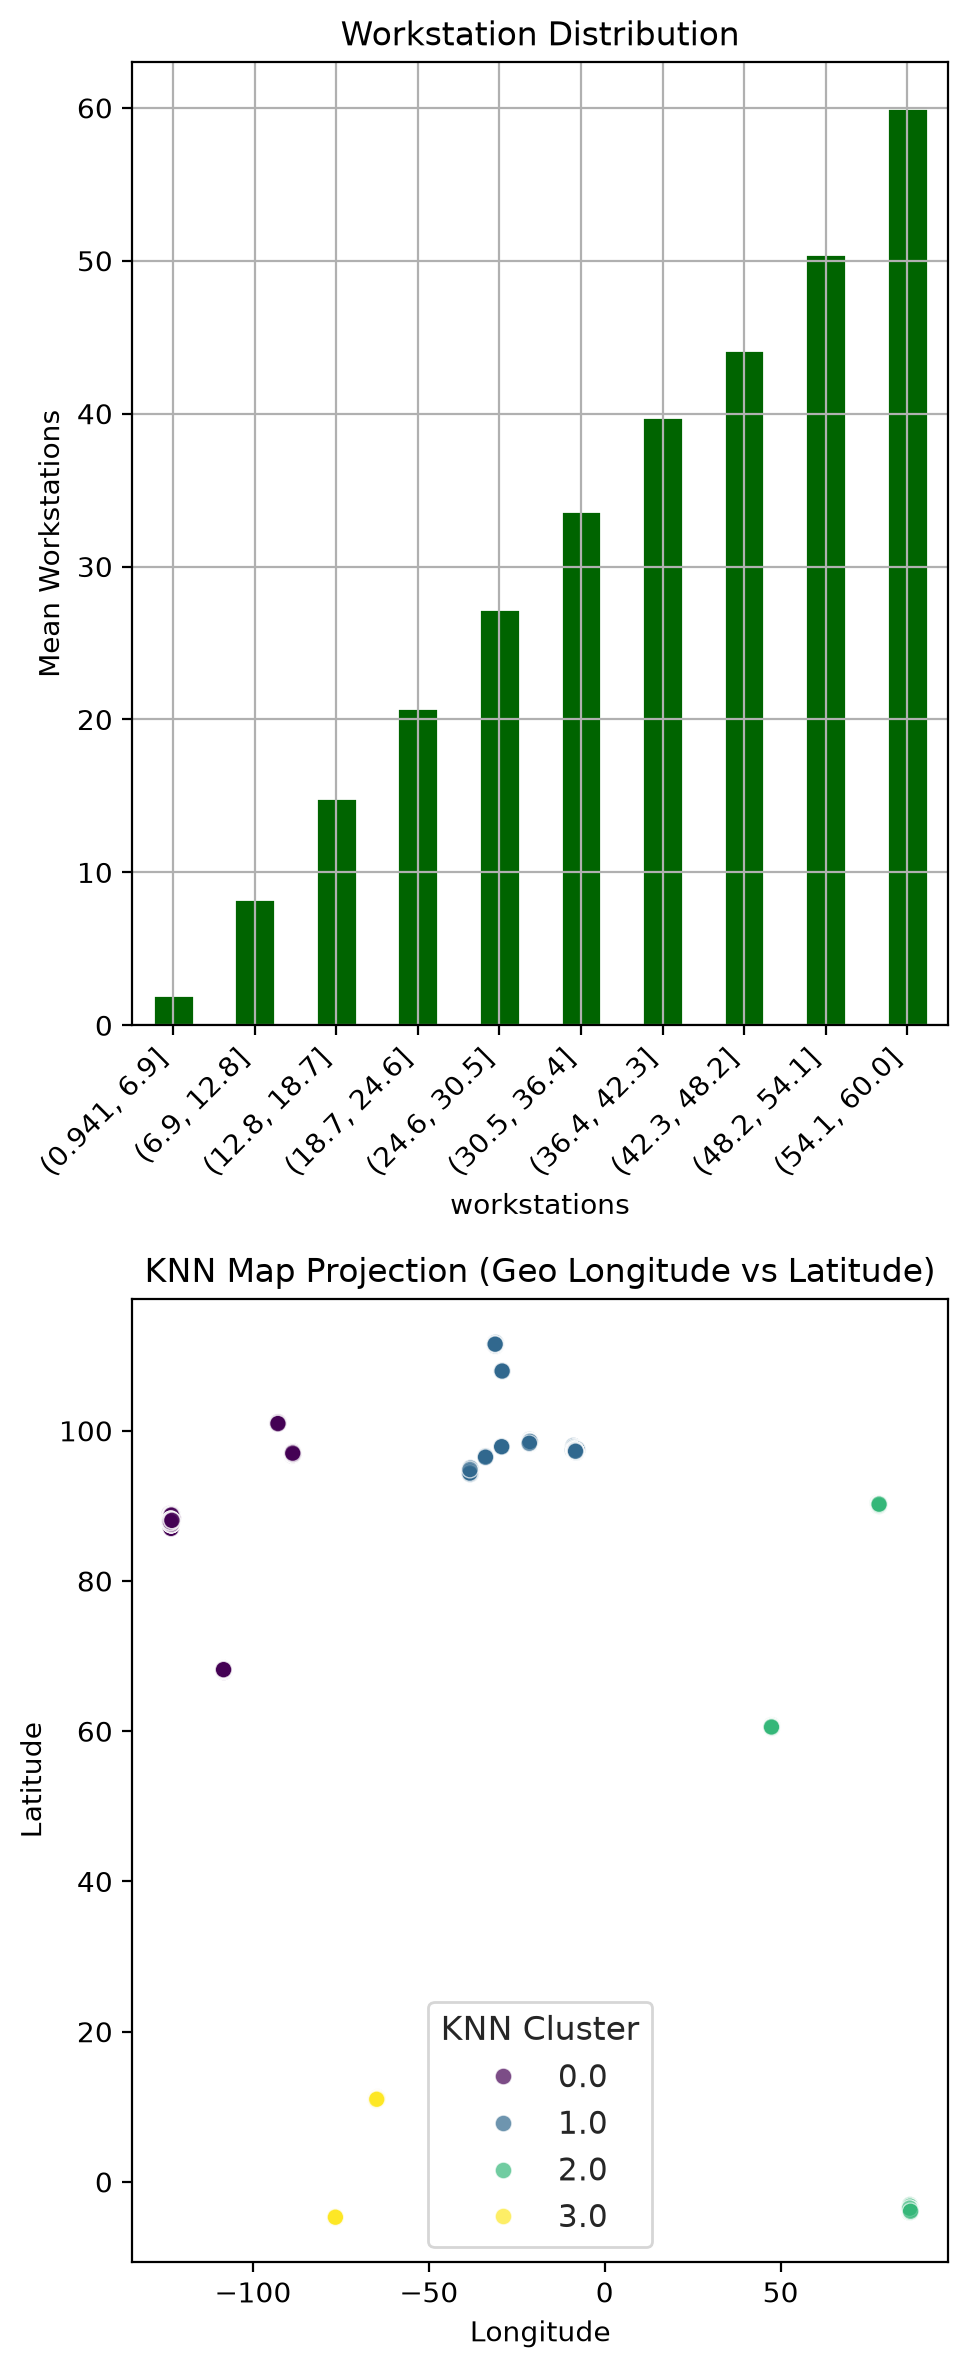

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Imports missing from the user snippet
from sklearn.neighbors import KNeighborsClassifier

# Set layout parameters
total_plots = 2
fig, axs = plt.subplots(total_plots, 1, figsize=(5, 12), layout="tight", dpi=200)
sns.set_theme(style="whitegrid")

# --- Plot 1: Workstation Distribution Bins ---
workstations = df["workstations"].dropna()
workstation_group = pd.cut(workstations, bins=10)

# Calculate means per bin for plotting values correctly
bin_means = workstations.groupby(workstation_group, observed=False).mean()
bin_means.plot(
    kind="bar", color="darkgreen", ax=axs[0], title="Workstation Distribution"
)
axs[0].set_ylabel("Mean Workstations")
axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=45, ha="right")

# --- Data Preparation & Dimensionality Reduction ---
X = df[["geo_lat", "geo_lon"]].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=1)
X_pca = pca.fit_transform(X_scaled)
df.loc[X.index, "PCA_1"] = X_pca.flatten()

# --- Clustering Execution ---
kmeans = KMeans(n_clusters=4, random_state=42, n_init="auto")
df.loc[X.index, "cluster_spatial"] = kmeans.fit_predict(X_scaled)
df.loc[X.index, "cluster_pca"] = kmeans.fit_predict(X_pca)

# KNN Classifier fitting to handle the "KNN cluster" logic on spatial labels
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_scaled, df.loc[X.index, "cluster_spatial"])
df.loc[X.index, "cluster_knn"] = knn.predict(X_scaled)

# --- Plot 2: 2D Spatial Layout (KNN Refined Labels) ---
sns.scatterplot(
    data=df.loc[X.index],
    x="geo_lon",
    y="geo_lat",
    hue="cluster_knn",
    palette="viridis",
    ax=axs[1],
    alpha=0.7,
)
axs[1].set_title("KNN Map Projection (Geo Longitude vs Latitude)")
axs[1].set_xlabel("Longitude")
axs[1].set_ylabel("Latitude")
axs[1].legend(title="KNN Cluster")

# --- Plot 3: 2D -> 1D Transformation Distribution ---
# Binned review counts combined with PCA mapping representation
if "review_count" in df.columns:
    df["review_bins"] = pd.qcut(df["review_count"], q=4, labels=False)
    hue_val = "review_bins"
    legend_title = "Review Count Quartile"
    palette_style = "magma"
else:
    hue_val = "cluster_pca"
    legend_title = "PCA Cluster"
    palette_style = "plasma"


plt.show()


In [9]:
# Train test split
from sklearn.model_selection import train_test_split

''' 
Initial splitting strategy with simple train, test and validation, 
test for testing individual model, 
validation set for ranking different model performances

Would upgrade for k-fold approach after base line
'''
raw_df = pd.read_csv(TRAIN_PATH)
y = raw_df.loc[:, 'price_tier']
X = raw_df.drop(
    columns=[
        'space_id',
        'price_tier'
    ]
)

X_train_val, X_test, y_train_val, y_test = train_test_split(X,y, test_size=0.2, random_state=32)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=32)

X_train.columns

Index(['operator_ref', 'operator_platform_age_years',
       'operator_platform_age_months', 'operator_active_years',
       'operator_active_months', 'operator_class', 'operator_certified',
       'operator_portfolio_size', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'borough', 'geo_lat', 'geo_lon',
       'space_class', 'access_type', 'max_seats', 'utility_rooms', 'zones',
       'workstations', 'facilities', 'snapshot_start_date',
       'snapshot_end_date', 'min_term_days', 'max_term_days', 'min_term_floor',
       'min_term_ceiling', 'max_term_floor', 'max_term_ceiling',
       'min_term_avg', 'max_term_avg', 'bookable', 'open_slots_a',
       'open_slots_b', 'open_slots_c', 'open_slots_d', 'review_count',
       'review_count_12m', 'review_count_30d', 'open_slots_e',
       'review_count_prev_yr', 'booked_load', 'first_review_date',
       'last_review_date', 'score_overall', 'score_accuracy',
       'score_condition', 'score_onboarding', 'score_support', 'score

In [10]:
# Feature encoding for categorical dataset load

oh_target = [
    'operator_certified',
    'operator_has_avatar',
    'operator_id_verified',
    'bookable',
    'compliance_status'
]
te_target = [
    'operator_class',
    'space_class',
    'metro',
    'zone'
]

oe_target = [
    'access_type'
]

num_targets = [col for col in X_train.columns if X_train[col].dtype in ['number', 'int64', 'float64']]
cat_targets = [col for col in X_train.columns if X_train[col].dtype in ['str', 'object']]

In [11]:
# Preprocessing pipeline for the dataset
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline


# Numerical preprocessing
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# One-hot encoding
oh_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Target encoding
te_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder(
        target_type='auto',
        smooth='auto'
    ))
])

# Ordinal encoding
oe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine all transformations
pipe = ColumnTransformer([
    ('numerical', num_pipe, num_targets),
    ('onehot', oh_pipe, oh_target),
    ('target', te_pipe, te_target),
    ('ordinal', oe_pipe, oe_target)
])

pipe.set_output(transform='pandas')

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('onehot', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [12]:
X.columns

Index(['operator_ref', 'operator_platform_age_years',
       'operator_platform_age_months', 'operator_active_years',
       'operator_active_months', 'operator_class', 'operator_certified',
       'operator_portfolio_size', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'borough', 'geo_lat', 'geo_lon',
       'space_class', 'access_type', 'max_seats', 'utility_rooms', 'zones',
       'workstations', 'facilities', 'snapshot_start_date',
       'snapshot_end_date', 'min_term_days', 'max_term_days', 'min_term_floor',
       'min_term_ceiling', 'max_term_floor', 'max_term_ceiling',
       'min_term_avg', 'max_term_avg', 'bookable', 'open_slots_a',
       'open_slots_b', 'open_slots_c', 'open_slots_d', 'review_count',
       'review_count_12m', 'review_count_30d', 'open_slots_e',
       'review_count_prev_yr', 'booked_load', 'first_review_date',
       'last_review_date', 'score_overall', 'score_accuracy',
       'score_condition', 'score_onboarding', 'score_support', 'score

In [13]:
X['access_type'].unique()

<StringArray>
['private_zone', 'whole_unit', 'managed_suite', 'shared_zone']
Length: 4, dtype: str

In [14]:
# Feature Engineering pipeline

def feature_extraction_pipeline(df):
    """ 
    Extracting feature from the root dataset

    Requirements
    years[active, total age] -> years bin -> ordinal encoding bins
    facilities -> facilities count, multilevel binarizer, bining feature counts, targeted encode

    review count distribution with operator requried
    Date based duration extractor

    geo location transformation into clusters along with targeted encoded cluster, pca extracted numerical bins

    Experimental enhancements
    operator_ref : binning transformation for binning into other based
    """
    pass

In [ ]:
# Model Arena

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# --- Import All 20 Classifiers ---
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron, PassiveAggressiveClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier

def benchmark_models(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Ridge Classifier": RidgeClassifier(random_state=42),
        "SGD Classifier": SGDClassifier(random_state=42),
        "Perceptron": Perceptron(random_state=42),
        "Passive Aggressive": PassiveAggressiveClassifier(random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Extra Tree": ExtraTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "Extra Trees": ExtraTreesClassifier(random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "Bagging Classifier": BaggingClassifier(random_state=42),
        "Gaussian NB": GaussianNB(),
        "Multinomial NB": MultinomialNB(),
        "Bernoulli NB": BernoulliNB(),
        "K-Neighbors": KNeighborsClassifier(),
    }
    
    results = []
    
    for name, model in models.items():
        try:
            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            
            # Using macro average to give equal weight to all classes
            f1 = f1_score(y_test, preds, average='macro')
            results.append({"Model": name, "Macro_F1_Score": f1, "Status": "Success"})
            sleep(10)
        except Exception as e:
            results.append({"Model": name, "Macro_F1_Score": 0.0, "Status": f"Failed: {str(e)}"})
            
    df_results = pd.DataFrame(results).sort_values(by="Macro_F1_Score", ascending=False).reset_index(drop=True)
    return df_results

df = benchmark_models(X_train_processed, y_train)

df.to_csv('Model_rank.csv', mode='w',index_label=False)


,Unnamed: 0,Model,Macro_F1_Score,Status
0,0.0,Logistic Regression,0.5761136596798309,Success
1,1.0,Ridge Classifier,0.5250114732117458,Success
2,2.0,Perceptron,0.4473709150262054,Success
3,3.0,SGD Classifier,0.4328496717416025,Success
4,NaN,Model,Macro_F1_Score,Status
5,0.0,Random Forest,0.5811790880869203,Success
6,1.0,Decision Tree,0.5600796850199105,Success
7,2.0,Extra Tree,0.557796081459749,Success
8,3.0,Passive Aggressive,0.48170084119781925,Success
9,NaN,Model,Macro_F1_Score,Status
